t = 0.01 s  T = 300.05 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.02 s  T = 300.10 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.03 s  T = 300.15 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.04 s  T = 300.20 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.05 s  T = 300.25 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.06 s  T = 300.30 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.07 s  T = 300.35 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.08 s  T = 300.40 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.09 s  T = 300.45 K  P_avg = 1.013e+05 Pa  P_after = 1.013e+05 Pa  n_in = 0 mol  m_gen = 0 g  q = 0 W/m3
t = 0.1 s 

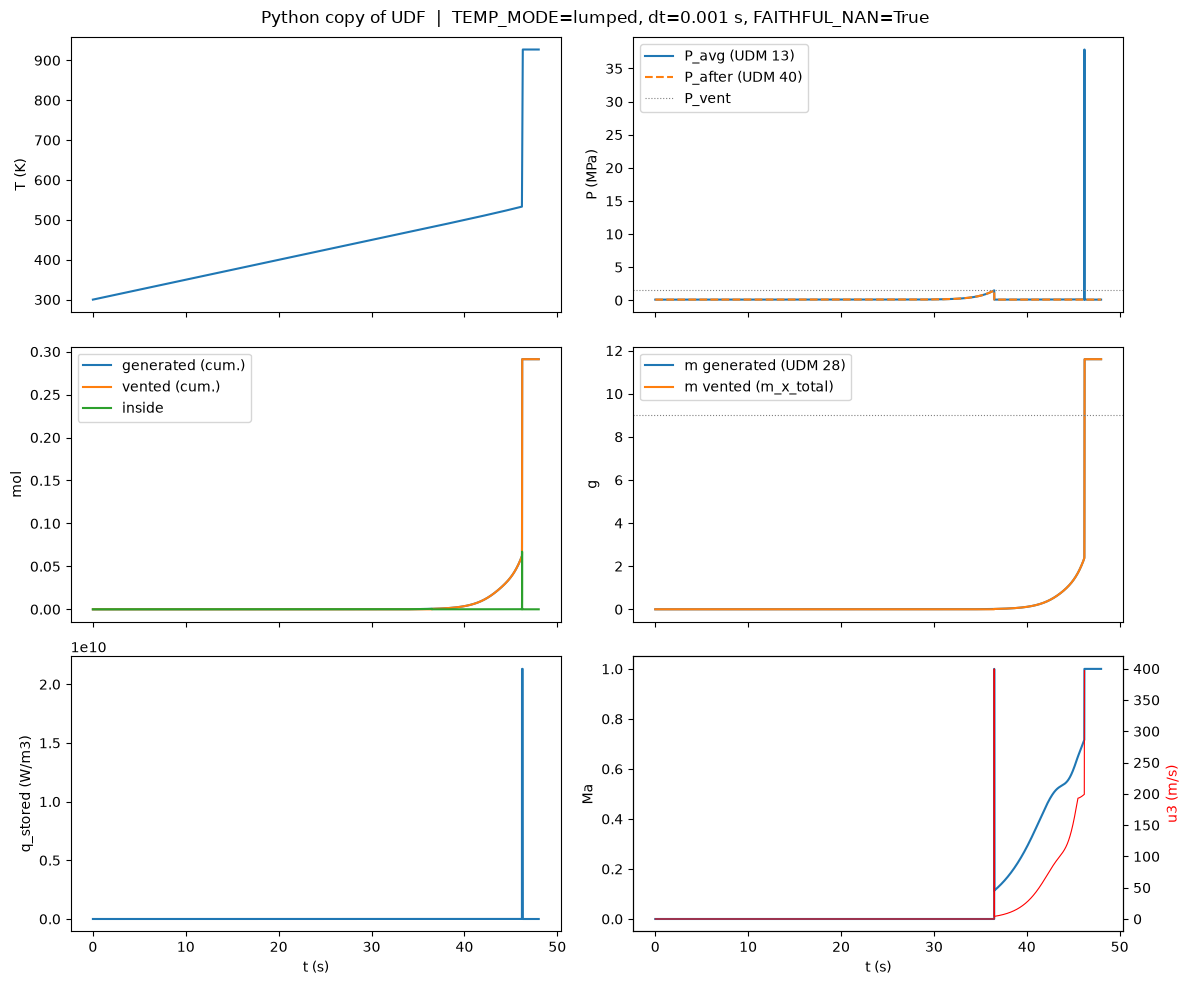

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.seterr(all="ignore")          # C does not stop on 0/0 or x/0, it gives nan/inf. Same here.
f64 = np.float64

# ----------------------------------------------------------------------------
# Run settings
# ----------------------------------------------------------------------------
DT           = 0.001        # time step (s)  - same as your Fluent case
T_FINAL      = 48.0      # end time (s)
TEMP_MODE    = "lumped"    # "dummy" or "lumped"
FAITHFUL_NAN = True       # True = copy the C behaviour exactly (see issue 4 above)

# ----------------------------------------------------------------------------
# Constants (#define in the UDF)
# ----------------------------------------------------------------------------
V_bat      = 0.0000165    # battery volume (m3)
H_chem     = 11740.0      # J
H_sc       = 17560.0      # J
rho        = 2600.0       # kg/m3
Cp         = 1720.0       # J/kg K
A_chem     = 0.92
b_chem     = 28.5
T_ref      = 533.15
T_chem     = 413.15
T_tr       = 533.15
C_chem_max = 12.0
C_elec_max = 12.0

# species order: 0 H2, 1 C2H4, 2 CH4, 3 CO, 4 CO2, 5 O2
MW      = [2.016, 28.05, 16.04, 28.01, 44.01, 32.0]   # g/mol
gama_sp = [1.4, 1.19, 1.3, 1.4, 1.29, 1.39]
NAMES   = ["H2", "C2H4", "CH4", "CO", "CO2", "O2"]

c_x_1_stoich = 2.2e5
c_x_2_stoich = 1.02e3
c_x_3_stoich = 5.6e3
c_x_4_stoich = 8e3

P_atm       = 101325.0
P_vent      = 1.5e6
V_void_init = 0.00000152
d_void      = 0.000007594
Area_valve  = 0.00003848
R_gas       = 8.314
TINY_VAL    = 1e-30
m_total     = 9.0

# dummy temperature (same as the UDF)
T_INITIAL   = 400.0
T_HEAT_RATE = 1.0
T_RATE_LATE = 1.0
T_SWITCH    = 2.0

# lumped mode only (18650: d = 18 mm, h = 65 mm). Approximation, not in the UDF.
A_SIDE      = math.pi * 0.018 * 0.065   # m2
T_START_LUMPED = 300.0                  # K
HEATER_FLUX = 1e5                       # W/m2


def dummy_T(time):
    if time < T_SWITCH:
        return T_INITIAL + T_HEAT_RATE * time
    return T_INITIAL + T_HEAT_RATE * T_SWITCH + (time - T_SWITCH) * T_RATE_LATE


# ----------------------------------------------------------------------------
# 1) DEFINE_INIT(init_concentrations)
# ----------------------------------------------------------------------------
def init_state():
    s = {}
    s["C_chem"] = f64(1.0)
    s["C_elec"] = f64(1.0)
    s["c_x"] = [f64(v) for v in
                [2.2e5, 1.02e3, 5.6e3, 8e3, 1.02e3, 7.6e2, 5.6e3, 1e3, 2.4e3, 0.12, 0.12]]
    s["G_x"]          = [f64(0.0)] * 6
    s["n_gen_accu"]   = [f64(0.0)] * 6
    s["n_exit_accu"]  = [f64(0.0)] * 6
    s["n_exit_rate"]  = [f64(0.0)] * 6
    s["n_inside"]     = [f64(0.0)] * 6
    s["m_x"]          = [f64(0.0)] * 6
    s["G_total"]           = f64(0.0)
    s["n_total_gen_accu"]  = f64(0.0)
    s["n_exit_total_accu"] = f64(0.0)
    s["n_exit_t"]          = f64(0.0)
    s["n_total_inside"]    = f64(0.0)
    s["m_tot_gen_accum"]   = f64(0.0)
    s["P_avg"]   = f64(P_atm)
    s["V_void"]  = f64(V_void_init)
    s["rho_mix"] = f64(0.0)
    s["gama"]    = f64(0.0)
    s["Ma"]      = f64(0.0)
    s["T2"]      = f64(300.0)
    s["u2"]      = f64(0.0)
    s["u3"]      = f64(0.0)
    s["P2"]      = f64(0.0)
    s["q_stored"]   = f64(0.0)
    s["valve_open"] = 0
    s["m_x_total"]  = f64(0.0)
    s["P_after"]    = f64(P_atm)
    s["n_left"]     = f64(0.0)
    return s


# ----------------------------------------------------------------------------
# 3) DEFINE_EXECUTE_AT_END(average_temp)  - one call = one time step
# ----------------------------------------------------------------------------
def average_temp(s, T, dt):
    exp = np.exp
    c_x = s["c_x"]
    R = [f64(0.0)] * 11

    # ---- gas-generating reactions (same order as the UDF: 0, 2, 1, 3, 4-7, 9, 10, 8)
    def limit_and_consume(k):
        if R[k] * dt > c_x[k]:
            R[k] = c_x[k] / dt
        c_x[k] = c_x[k] - R[k] * dt
        if c_x[k] < .00001:
            c_x[k] = f64(0.0)

    if T > 413.15 and s["m_tot_gen_accum"] < m_total:
        R[0] = 1.917e25 * c_x[0] * exp(-2.86e5 / (R_gas * T)) * exp(-c_x[0] / c_x_1_stoich)
        limit_and_consume(0)
        R[2] = 4e28 * c_x[2] * exp(-4.7e5 / (R_gas * T)) * exp(-c_x[2] / c_x_3_stoich)
        limit_and_consume(2)
        R[1] = 1.95e20 * c_x[1] * exp(-2e5 / (R_gas * T)) * exp(-c_x[1] / c_x_2_stoich)
        limit_and_consume(1)
        R[3] = 4e28 * c_x[3] * exp(-4.7e5 / (R_gas * T)) * exp(-c_x[3] / c_x_4_stoich)
        limit_and_consume(3)
        for k in range(4, 8):                       # reactions 5 to 8
            R[k] = 5.14e25 * c_x[k] * exp(-2.74e5 / (R_gas * T))
            limit_and_consume(k)
        R[9] = 1.75e9 * c_x[9] * exp(-1.1495e5 / (R_gas * T))
        limit_and_consume(9)
        R[10] = 1.077e12 * c_x[10] * exp(-1.5888e5 / (R_gas * T))
        limit_and_consume(10)
        R[8] = 7.88e25 * c_x[8] * exp(-2.81e5 / (R_gas * T))
        limit_and_consume(8)

    # ---- generation rate of each species
    G = s["G_x"] = [f64(0.0)] * 6
    if s["m_tot_gen_accum"] < m_total:
        G[0] = 0.5 * R[0] - R[2]
        G[1] = R[1] + R[8]
        G[2] = 2 * R[2]
        G[3] = R[3]
        G[4] = 3 * R[4] + 4 * R[5] + 3 * R[6] + R[7] + R[8] - 2 * R[3]
        G[5] = R[9] + R[10] + 0.5 * R[8] - 2.5 * R[4] - 4 * R[5] - 3 * R[6]

    G_total = f64(0.0)
    for k in range(6):
        if G[k] < 0.0:
            G[k] = f64(0.0)
        G_total += G[k]
    s["G_total"] = G_total

    # ---- moles generated this step and accumulated
    n_gen = [G[k] * dt * V_bat for k in range(6)]
    for k in range(6):
        s["n_gen_accu"][k] += n_gen[k]
    n_total_gen = G_total * dt * V_bat
    s["n_total_gen_accu"] += n_total_gen
    for k in range(6):
        s["m_tot_gen_accum"] += n_gen[k] * MW[k]

    # ---- void volume
    if s["m_x_total"] <= 0:
        s["V_void"] = f64(V_void_init)
    else:
        if s["n_total_gen_accu"] > TINY_VAL:
            s["V_void"] = V_void_init + (s["m_x_total"] / m_total) * d_void
        else:
            s["V_void"] = f64(V_void_init)

    # ---- moles inside and internal pressure  (MOVED: now BEFORE venting, as in the 14-11 UDF)
    #      -> includes this step's generation, nothing vented yet this step
    s["n_total_inside"] = s["n_total_gen_accu"] - s["n_exit_total_accu"]
    if s["n_total_inside"] < 1e-10:
        s["n_total_inside"] = f64(0.0)
    for k in range(6):
        s["n_inside"][k] = s["n_gen_accu"][k] - s["n_exit_accu"][k]
        if s["n_inside"][k] < 1e-10:          # NaN < x is False -> NaN stays, as in C
            s["n_inside"][k] = f64(0.0)

    if s["n_total_inside"] > 0 and s["V_void"] > 0:
        s["P_avg"] = (s["n_total_inside"] * R_gas * T) / s["V_void"] + P_atm
    else:
        s["P_avg"] = f64(P_atm)

    if s["P_avg"] >= 1.5e6:
        s["valve_open"] = 1

    # ---- Mach number (uses THIS step's P_avg; gama still from the previous step)
    P_avg, gama = s["P_avg"], s["gama"]
    if s["valve_open"] == 1 and P_avg > P_atm:
        if (P_atm / P_avg) > (2 / (gama + 1)) ** (gama / (gama - 1)):
            s["Ma"] = np.sqrt((2 / (gama - 1)) * ((P_avg / P_atm) ** ((gama - 1) / gama) - 1))
        else:
            s["Ma"] = f64(1.0)
    Ma = s["Ma"]                                     # keeps old value otherwise (as in C)

    # ---- mixture gamma and density (uses n_inside computed above, before venting)
    mass = f64(0.0)
    gama_sum = f64(0.0)
    for k in range(6):
        mass += s["n_inside"][k] * MW[k]
        gama_sum += gama_sp[k] * s["n_inside"][k] * MW[k]
    gama = gama_sum / mass if mass > 0.0 else f64(1.4)   # NaN mass -> 1.4, like C
    s["gama"] = gama
    s["rho_mix"] = (mass / 1000) / s["V_void"]

    # ---- valve temperature and velocity
    T2 = T / (1.0 + ((gama - 1.0) / 2.0) * Ma * Ma)
    if mass > 0 and s["n_total_inside"] > 0:
        u2 = Ma * np.sqrt(gama * ((R_gas * 1000) / (mass / s["n_total_inside"])) * T2)
    else:
        u2 = f64(0.0)

    if Ma < 1:
        P2 = f64(P_atm)
        u3 = u2 * 0.7
    else:
        P2 = P_avg / (1.0 + (gama - 1.0) / 2.0) ** (gama / (gama - 1))
        P3 = P_atm
        u3 = 0.7 * (u2 - ((P3 - P2) / (s["rho_mix"] * u2)))
    s["T2"], s["u2"], s["P2"], s["u3"] = T2, u2, P2, u3

    # ---- venting (capped at what is inside now, including this step's generation)
    if s["valve_open"] == 1 and T2 > 0 and u2 > 0 and s["n_total_inside"] > 0:
        n_exit_t = (u3 * Area_valve * P2) / (R_gas * T2)
        if n_exit_t * dt > s["n_total_inside"]:
            n_exit_t = s["n_total_inside"] / dt
        s["n_exit_total_accu"] += n_exit_t * dt
        for k in range(6):
            if FAITHFUL_NAN:
                frac = n_gen[k] / n_total_gen                     # 0/0 -> nan, as in C
            else:
                frac = s["n_inside"][k] / s["n_total_inside"]     # suggested fix
            s["n_exit_rate"][k] = frac * n_exit_t
            s["n_exit_accu"][k] += s["n_exit_rate"][k] * dt
    else:
        n_exit_t = f64(0.0)
        s["n_exit_rate"] = [f64(0.0)] * 6
    s["n_exit_t"] = n_exit_t

    # ---- vent mass flux per species
    if s["valve_open"] == 1 and s["m_x_total"] <= m_total:
        for k in range(6):
            s["m_x"][k] = (s["n_exit_rate"][k] * MW[k]) / (1000 * Area_valve)
            s["m_x_total"] += s["n_exit_rate"][k] * MW[k] * dt

    # ---- pressure after venting
    n_left = s["n_total_gen_accu"] - s["n_exit_total_accu"]
    if n_left < 1e-10:
        n_left = f64(0.0)
    s["P_after"] = n_left * R_gas * T / s["V_void"] + P_atm if n_left > 0.0 else f64(P_atm)
    s["n_left"] = n_left
    # NOTE: n_inside / n_total_inside / P_avg are NOT updated after venting (same as the UDF,
    # where that block is commented out). So UDM 13 (P_avg) and UDM 14 (n_in) are PRE-vent values.

    # ---- chemical heat
    C_chem = s["C_chem"]
    if T > T_chem and T <= T_tr and C_chem > 0 and C_chem <= 1:
        dC_chem_dt = (Cp / H_chem) * A_chem * rho * V_bat * (T / T_ref) ** b_chem
    elif T > T_tr and C_chem > 0 and C_chem <= 1:
        dC_chem_dt = C_chem_max
    else:
        dC_chem_dt = 0.0
    if C_chem < 0:
        C_chem = f64(0.0)
    if dC_chem_dt * dt > C_chem:
        dC_chem_dt = C_chem / dt
    C_chem = C_chem - dC_chem_dt * dt
    q_chem = (1.0 / V_bat) * H_chem * dC_chem_dt
    s["C_chem"] = C_chem

    # ---- electrical (short-circuit) heat
    C_elec = s["C_elec"]
    if T > T_tr and C_elec >= 0 and C_elec <= 1:
        dC_elec_dt = C_elec_max
    else:
        dC_elec_dt = 0.0
    if dC_elec_dt * dt > C_elec:
        dC_elec_dt = C_elec / dt
    C_elec = C_elec - dC_elec_dt * dt
    q_elec = (1.0 / V_bat) * H_sc * dC_elec_dt
    s["C_elec"] = C_elec

    s["q_stored"] = q_chem + q_elec       # used during the NEXT step
    s["R"] = R
    return s


# ----------------------------------------------------------------------------
# Time loop (plays the role of Fluent)
# ----------------------------------------------------------------------------
def run():
    s = init_state()
    n_steps = int(round(T_FINAL / DT))
    keys = ["t", "T", "P_avg", "P_after", "n_gen_cum", "n_exit_cum", "n_inside",
            "m_gen", "m_vented", "V_void", "Ma", "u3", "n_exit_rate", "q_stored",
            "C_chem", "C_elec", "valve_open", "gama"]
    h = {k: [] for k in keys}

    T_lumped = T_START_LUMPED
    for n in range(1, n_steps + 1):
        t = n * DT                                   # CURRENT_TIME at end of step n
        if TEMP_MODE == "dummy":
            T = dummy_T(t)
        else:
            # heater uses T_avg of the previous step; q_stored is from the previous step
            Q_heater = HEATER_FLUX * A_SIDE if T_lumped < 533.15 else 0.0
            T_lumped += DT * (Q_heater + s["q_stored"] * V_bat) / (rho * V_bat * Cp)
            T = T_lumped

        average_temp(s, f64(T), DT)

        h["t"].append(t); h["T"].append(T)
        h["P_avg"].append(s["P_avg"]); h["P_after"].append(s["P_after"])
        h["n_gen_cum"].append(s["n_total_gen_accu"]); h["n_exit_cum"].append(s["n_exit_total_accu"])
        h["n_inside"].append(s["n_total_inside"]); h["m_gen"].append(s["m_tot_gen_accum"])
        h["m_vented"].append(s["m_x_total"]); h["V_void"].append(s["V_void"])
        h["Ma"].append(s["Ma"]); h["u3"].append(s["u3"]); h["n_exit_rate"].append(s["n_exit_t"])
        h["q_stored"].append(s["q_stored"]); h["C_chem"].append(s["C_chem"])
        h["C_elec"].append(s["C_elec"]); h["valve_open"].append(s["valve_open"])
        h["gama"].append(s["gama"])

        # same console line as Message() in the UDF
        if n % 10 == 0 or s["n_exit_t"] > 0:
            print(f"t = {t:g} s  T = {T:.2f} K  P_avg = {s['P_avg']:.4g} Pa  "
                  f"P_after = {s['P_after']:.4g} Pa  n_in = {s['n_total_inside']:.4g} mol  "
                  f"m_gen = {s['m_tot_gen_accum']:.4g} g  q = {s['q_stored']:.4g} W/m3")
    return {k: np.array(v, dtype=float) for k, v in h.items()}


def plot(h, fname="udf_python_results.png"):
    fig, ax = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
    ax[0, 0].plot(h["t"], h["T"]); ax[0, 0].set_ylabel("T (K)")
    ax[0, 1].plot(h["t"], h["P_avg"] / 1e6, label="P_avg (UDM 13)")
    ax[0, 1].plot(h["t"], h["P_after"] / 1e6, "--", label="P_after (UDM 40)")
    ax[0, 1].axhline(P_vent / 1e6, color="grey", lw=0.8, ls=":", label="P_vent")
    ax[0, 1].set_ylabel("P (MPa)"); ax[0, 1].legend()
    ax[1, 0].plot(h["t"], h["n_gen_cum"], label="generated (cum.)")
    ax[1, 0].plot(h["t"], h["n_exit_cum"], label="vented (cum.)")
    ax[1, 0].plot(h["t"], h["n_inside"], label="inside")
    ax[1, 0].set_ylabel("mol"); ax[1, 0].legend()
    ax[1, 1].plot(h["t"], h["m_gen"], label="m generated (UDM 28)")
    ax[1, 1].plot(h["t"], h["m_vented"], label="m vented (m_x_total)")
    ax[1, 1].axhline(m_total, color="grey", lw=0.8, ls=":")
    ax[1, 1].set_ylabel("g"); ax[1, 1].legend()
    ax[2, 0].plot(h["t"], h["q_stored"]); ax[2, 0].set_ylabel("q_stored (W/m3)")
    ax[2, 0].set_xlabel("t (s)")
    ax[2, 1].plot(h["t"], h["Ma"], label="Ma")
    ax2 = ax[2, 1].twinx(); ax2.plot(h["t"], h["u3"], "r", lw=0.8, label="u3 (m/s)")
    ax[2, 1].set_ylabel("Ma"); ax2.set_ylabel("u3 (m/s)", color="r")
    ax[2, 1].set_xlabel("t (s)")
    fig.suptitle(f"Python copy of UDF  |  TEMP_MODE={TEMP_MODE}, dt={DT} s, FAITHFUL_NAN={FAITHFUL_NAN}")
    fig.tight_layout()
    fig.savefig(fname, dpi=130)
    print("saved", fname)


if __name__ == "__main__":
    hist = run()
    plot(hist)
    # np.savetxt("udf_python_results.csv",
    #            np.column_stack([hist[k] for k in hist]),
    #            delimiter=",", header=",".join(hist.keys()), comments="")
    # print("saved udf_python_results.csv")